# Exploratory Data Analysis (EDA) for RAG Chatbot
This notebook analyzes the document corpus used for the Retrieval-Augmented Generation (RAG) system. 
In a RAG system, the 'dataset' consists of documents. Our EDA focuses on:
1. Document text length and structure.
2. Text chunking analysis (crucial for vector embedding).
3. Word frequency distribution to understand the primary topics.


In [1]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Load the PDF Document
# We will use the test PDF generated earlier.
pdf_path = '../knowledge_pdf/nexus_test_document.pdf'
loader = PyPDFLoader(pdf_path)
documents = loader.load()

print(f"Number of pages loaded: {len(documents)}")


C:\Users\LE\AppData\Local\Temp\ipykernel_7764\4019213616.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
None of PyTorch, TensorFlow >= 2.0, or Flax have been found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Number of pages loaded: 1


In [2]:
# Extract raw text from all pages
full_text = " ".join([doc.page_content for doc in documents])
print(f"Total characters in document: {len(full_text)}")
print(f"Total words in document: {len(full_text.split())}")


Total characters in document: 728
Total words in document: 103


Total chunks created: 2


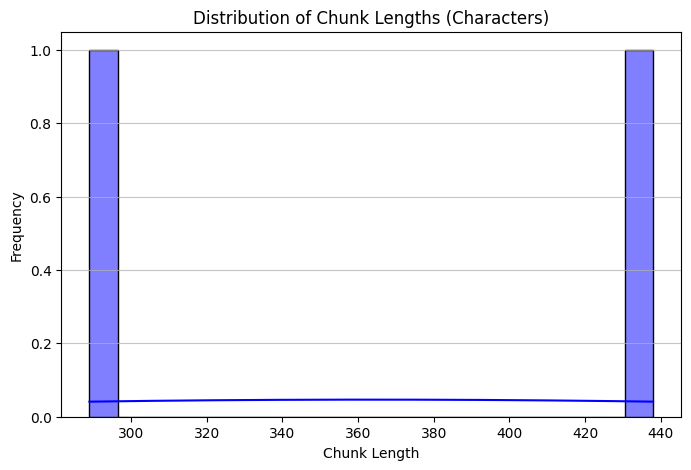

In [3]:
# Text Chunking Analysis
# In RAG, we split text into chunks before embedding. 
# We need to analyze if our chunk size fits the context window properly.

text_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = text_splitter.split_documents(documents)

chunk_lengths = [len(chunk.page_content) for chunk in chunks]
print(f"Total chunks created: {len(chunks)}")

# Plotting Chunk Size Distribution
plt.figure(figsize=(8, 5))
sns.histplot(chunk_lengths, bins=20, kde=True, color='blue')
plt.title('Distribution of Chunk Lengths (Characters)')
plt.xlabel('Chunk Length')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()


C:\Users\LE\AppData\Local\Temp\ipykernel_7764\11603808.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts_list), y=list(words_list), palette='viridis')


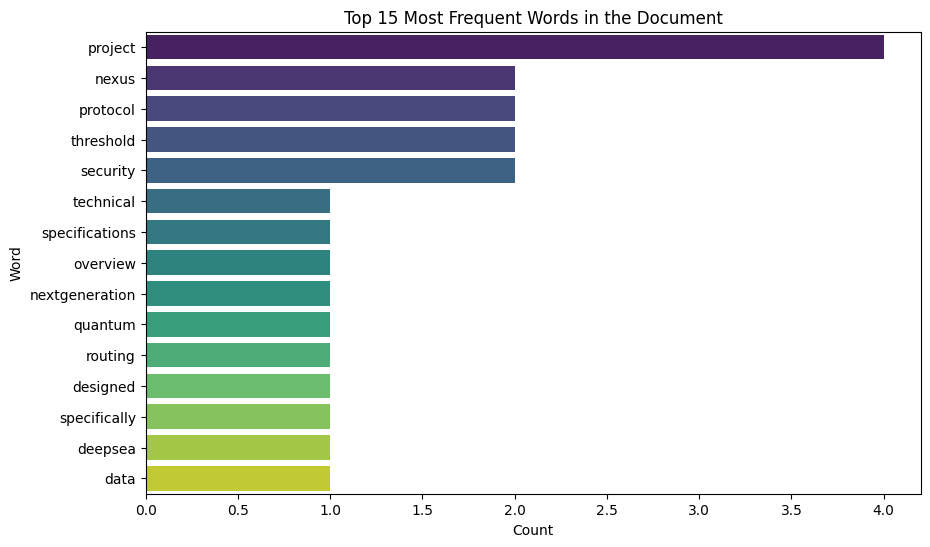

In [4]:
# Word Frequency Analysis
# Identifying the most common words helps us understand the document's main topics.

def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text).lower()
    return text

cleaned_text = clean_text(full_text)
words = cleaned_text.split()

# Remove basic stop words manually for simplicity
stop_words = {'the', 'a', 'to', 'of', 'and', 'in', 'is', 'for', 'on', 'this', 'that', 'with', 'as', 'by', 'are'}
filtered_words = [w for w in words if w not in stop_words and len(w) > 2]

word_counts = Counter(filtered_words)
common_words = word_counts.most_common(15)

# Plotting Top Words
words_list, counts_list = zip(*common_words)

plt.figure(figsize=(10, 6))
sns.barplot(x=list(counts_list), y=list(words_list), palette='viridis')
plt.title('Top 15 Most Frequent Words in the Document')
plt.xlabel('Count')
plt.ylabel('Word')
plt.show()
